<a href="https://colab.research.google.com/github/yadavswarup901-dotcom/Heart-Disease-Prediction-Using-Machine-Learning/blob/main/Swarup_Y_K_(20241CSE0612)_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
# ==========================================
# CELL 1: IMPORT LIBRARIES
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    roc_curve,
    roc_auc_score
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [7]:
# ==========================================
# CELL 2: EXTRACT AND LOAD HEART DATASET
# ==========================================

import os
import zipfile
import glob
import pandas as pd

# Get uploaded filename
file_name = next(iter(uploaded.keys()))

print("Uploaded File:", file_name)

# Check whether uploaded file is ZIP or CSV
if file_name.lower().endswith('.zip'):

    extract_path = "heart_dataset"

    os.makedirs(extract_path, exist_ok=True)

    # Extract ZIP file
    with zipfile.ZipFile(file_name, 'r') as zip_ref:
        zip_ref.extractall(extract_path)

    print("\nZIP file extracted successfully!")

    # Find CSV files
    csv_files = glob.glob(
        os.path.join(extract_path, "**", "*.csv"),
        recursive=True
    )

    if not csv_files:
        raise FileNotFoundError("No CSV file found inside the ZIP!")

    # Load the first CSV file
    df = pd.read_csv(csv_files[0])

elif file_name.lower().endswith('.csv'):

    df = pd.read_csv(file_name)

else:
    raise ValueError("Please upload a CSV or ZIP file.")

# Display dataset
print("\nHeart Disease Dataset Loaded Successfully!")

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Columns:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Uploaded File: archive.zip

ZIP file extracted successfully!

Heart Disease Dataset Loaded Successfully!

First 5 Rows:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1



Dataset Shape:
(303, 14)

Dataset Columns:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB

Missing Values:
age         0

In [8]:
# ==========================================
# CELL 3: EXPLORATORY DATA ANALYSIS
# ==========================================

print("Dataset Description:")
display(df.describe())

print("\nTarget Distribution:")
print(df['target'].value_counts())

print("\nTarget Percentage:")
print(df['target'].value_counts(normalize=True) * 100)

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Dataset Description:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.683168,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,0.326733,1.039604,1.399340,0.729373,2.313531,0.544554
std,9.082101,0.466011,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,0.469794,1.161075,0.616226,1.022606,0.612277,0.498835
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000



Target Distribution:
target
1    165
0    138
Name: count, dtype: int64

Target Percentage:
target
1    54.455446
0    45.544554
Name: proportion, dtype: float64

Duplicate Rows:
1

Total Missing Values:
0


In [9]:
# ==========================================
# CELL 4: SEPARATE INPUT FEATURES AND TARGET
# ==========================================

# Input features
X = df.drop('target', axis=1)

# Target variable
y = df['target']

print("Input Features (X):")
display(X.head())

print("\nTarget Variable (y):")
display(y.head())

print("\nNumber of Input Features:", X.shape[1])
print("Number of Target Values:", y.shape[0])

print("\nTarget Class Distribution:")
print(y.value_counts())

print("\nTarget Labels:")
print("0 = No Heart Disease")
print("1 = Heart Disease Present")

Input Features (X):


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2



Target Variable (y):


,target
0,1
1,1
2,1
3,1
4,1



Number of Input Features: 13
Number of Target Values: 303

Target Class Distribution:
target
1    165
0    138
Name: count, dtype: int64

Target Labels:
0 = No Heart Disease
1 = Heart Disease Present


In [10]:
# ==========================================
# CELL 5: TRAIN-TEST SPLIT
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Dataset Split Successfully!")

print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Dataset Split Successfully!

Training Data Shape: (242, 13)
Testing Data Shape: (61, 13)

Training Target Shape: (242,)
Testing Target Shape: (61,)


In [11]:
# ==========================================
# CELL 6: DATA PREPROCESSING
# ==========================================

X_train = X_train.copy()
X_test = X_test.copy()

print("Missing Values in Training Data:")
print(X_train.isnull().sum())

print("\nMissing Values in Testing Data:")
print(X_test.isnull().sum())

print("\nData Preprocessing Completed Successfully!")

Missing Values in Training Data:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
dtype: int64

Missing Values in Testing Data:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
dtype: int64

Data Preprocessing Completed Successfully!


In [12]:
# ==========================================
# CELL 7: BUILD AND TRAIN MODEL
# ==========================================

model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(max_iter=1000))
])

# Train the model
model.fit(X_train, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [13]:
# ==========================================
# CELL 8: MODEL PREDICTION
# ==========================================

y_pred = model.predict(X_test)

print("Predictions Generated Successfully!")

print("\nActual Values (First 10):")
print(y_test.iloc[:10].values)

print("\nPredicted Values (First 10):")
print(y_pred[:10])

Predictions Generated Successfully!

Actual Values (First 10):
[0 0 0 0 0 0 1 0 1 0]

Predicted Values (First 10):
[0 0 0 1 1 0 1 0 1 1]


In [14]:
# ==========================================
# CELL 9: MODEL EVALUATION
# ==========================================

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, zero_division=0
)

recall = recall_score(
    y_test, y_pred, zero_division=0
)

f1 = f1_score(
    y_test, y_pred, zero_division=0
)

print("========== MODEL PERFORMANCE ==========")

print("Accuracy  :", round(accuracy, 4))
print("Precision :", round(precision, 4))
print("Recall    :", round(recall, 4))
print("F1 Score  :", round(f1, 4))

print("\n========== CLASSIFICATION REPORT ==========")

print(classification_report(
    y_test,
    y_pred,
    target_names=['No Heart Disease', 'Heart Disease'],
    zero_division=0
))

========== MODEL PERFORMANCE ==========
Accuracy  : 0.8033
Precision : 0.7692
Recall    : 0.9091
F1 Score  : 0.8333

========== CLASSIFICATION REPORT ==========
                  precision    recall  f1-score   support

No Heart Disease       0.86      0.68      0.76        28
   Heart Disease       0.77      0.91      0.83        33

        accuracy                           0.80        61
       macro avg       0.82      0.79      0.80        61
    weighted avg       0.81      0.80      0.80        61



In [15]:
# ==========================================
# CELL 10: CONFUSION MATRIX
# ==========================================

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

tn, fp, fn, tp = cm.ravel()

print("\nTrue Negative:", tn)
print("False Positive:", fp)
print("False Negative:", fn)
print("True Positive:", tp)

Confusion Matrix:
[[19  9]
 [ 3 30]]

True Negative: 19
False Positive: 9
False Negative: 3
True Positive: 30


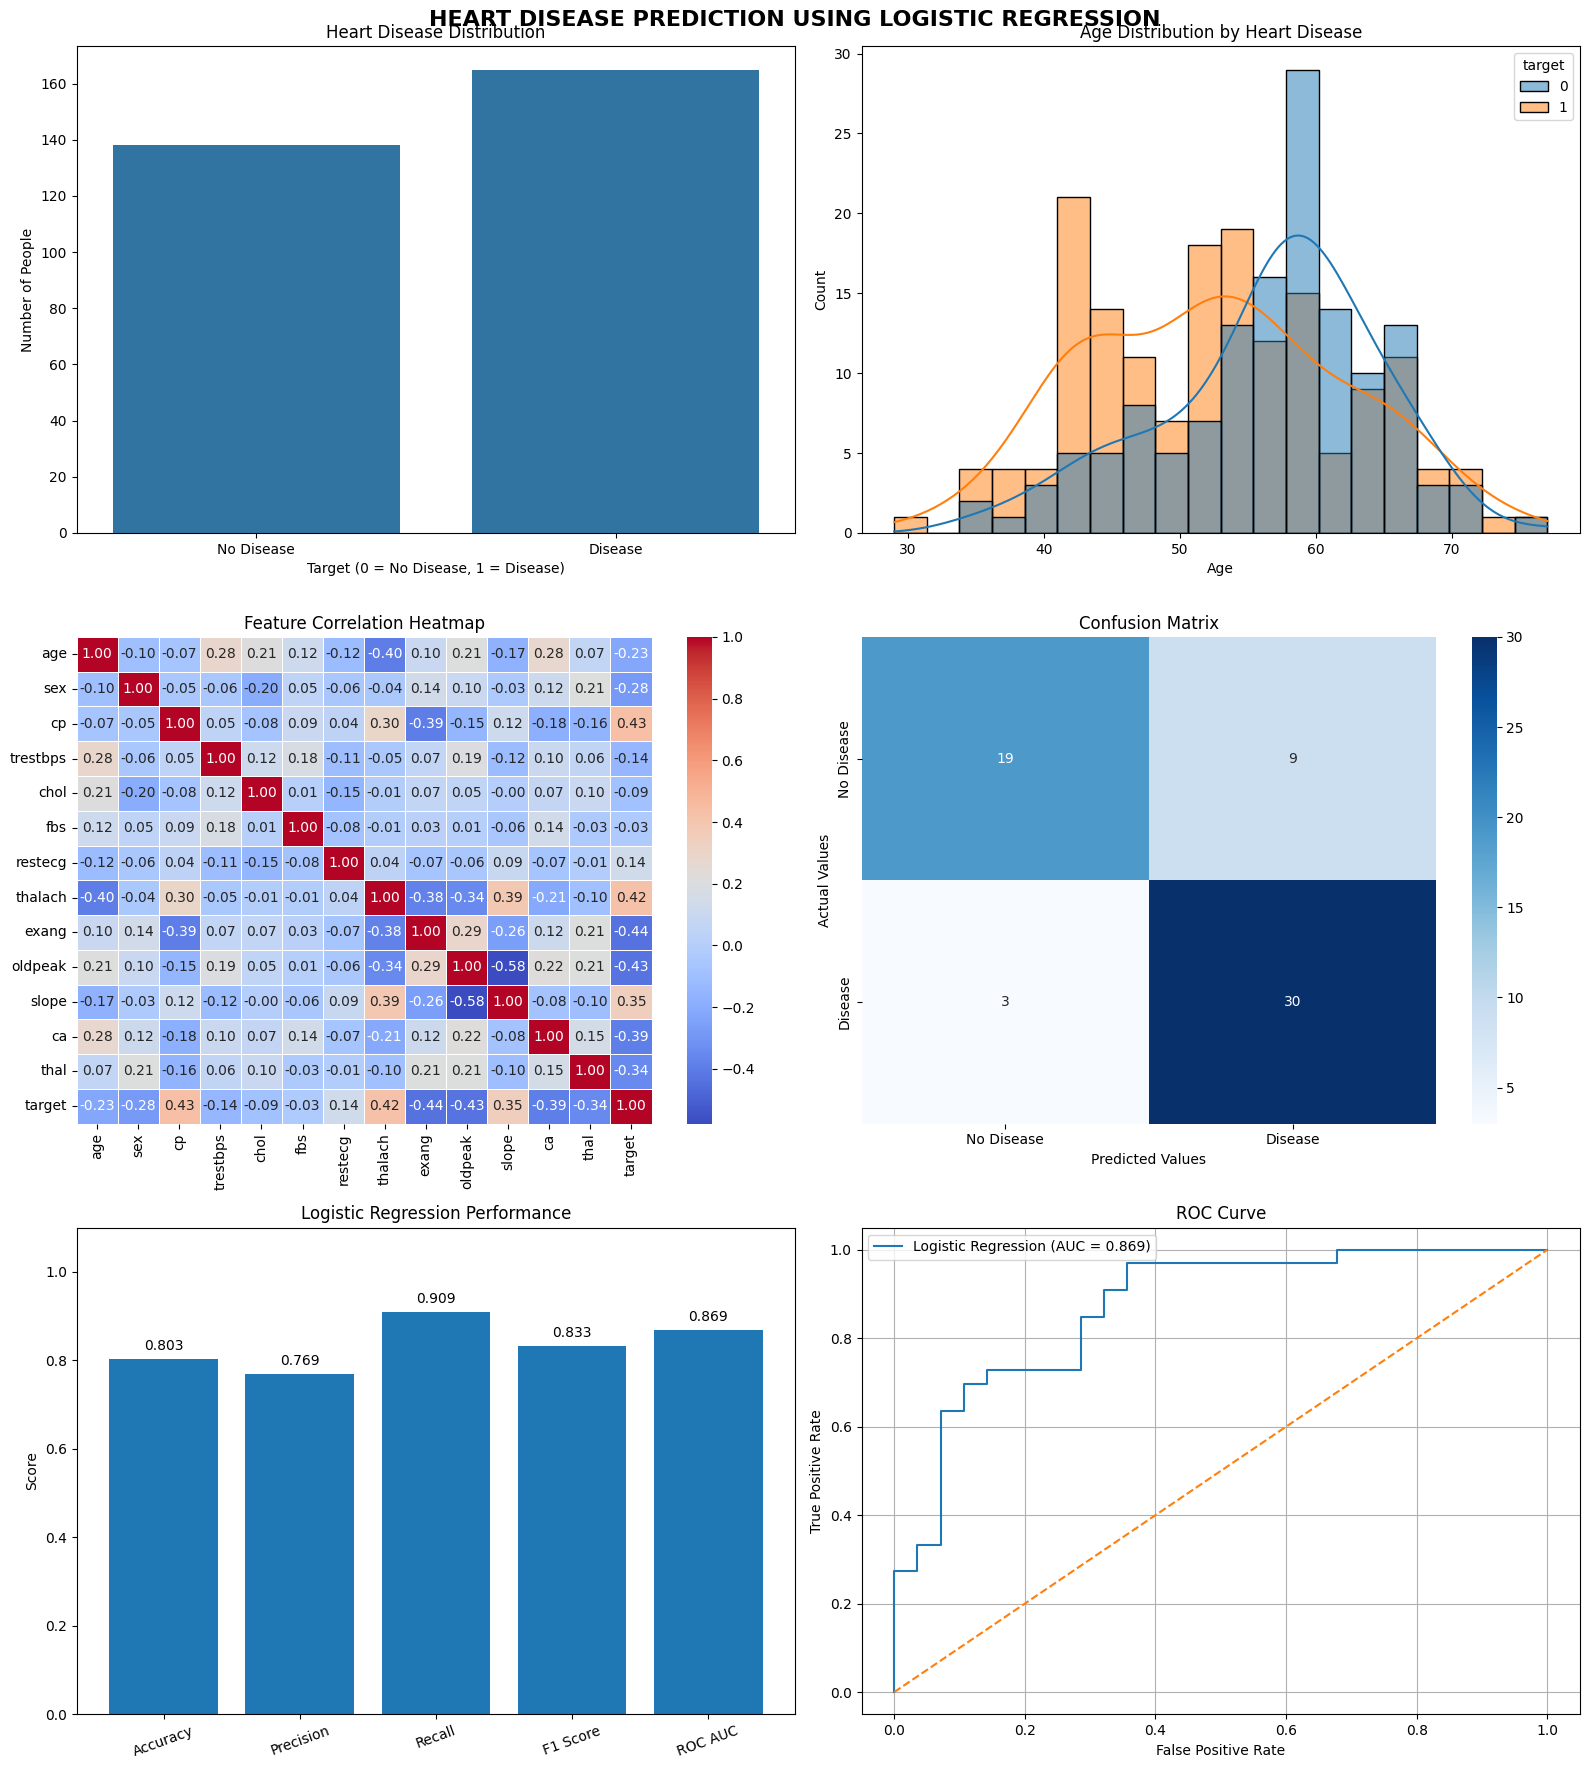


========== FINAL MODEL RESULTS ==========
Accuracy  : 0.8033
Precision : 0.7692
Recall    : 0.9091
F1 Score  : 0.8333
ROC AUC   : 0.8690

========== CLASSIFICATION REPORT ==========
                  precision    recall  f1-score   support

No Heart Disease       0.86      0.68      0.76        28
   Heart Disease       0.77      0.91      0.83        33

        accuracy                           0.80        61
       macro avg       0.82      0.79      0.80        61
    weighted avg       0.81      0.80      0.80        61



In [16]:
# ==========================================
# CELL 11: COMPLETE PROJECT VISUALIZATION
# ==========================================

# Generate prediction probabilities
y_prob = model.predict_proba(X_test)[:, 1]

# Calculate performance metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)

# Create visualization layout
fig, axes = plt.subplots(3, 2, figsize=(16, 18))

# 1. Target Distribution
sns.countplot(data=df, x='target', ax=axes[0, 0])
axes[0, 0].set_title("Heart Disease Distribution")
axes[0, 0].set_xlabel("Target (0 = No Disease, 1 = Disease)")
axes[0, 0].set_ylabel("Number of People")
axes[0, 0].set_xticks([0, 1])
axes[0, 0].set_xticklabels(['No Disease', 'Disease'])

# 2. Age Distribution
sns.histplot(
    data=df,
    x='age',
    hue='target',
    bins=20,
    kde=True,
    ax=axes[0, 1]
)
axes[0, 1].set_title("Age Distribution by Heart Disease")
axes[0, 1].set_xlabel("Age")
axes[0, 1].set_ylabel("Count")

# 3. Correlation Heatmap
sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    ax=axes[1, 0]
)
axes[1, 0].set_title("Feature Correlation Heatmap")

# 4. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Disease', 'Disease'],
    yticklabels=['No Disease', 'Disease'],
    ax=axes[1, 1]
)
axes[1, 1].set_title("Confusion Matrix")
axes[1, 1].set_xlabel("Predicted Values")
axes[1, 1].set_ylabel("Actual Values")

# 5. Model Performance
metrics = {
    'Accuracy': accuracy,
    'Precision': precision,
    'Recall': recall,
    'F1 Score': f1,
    'ROC AUC': roc_auc
}

axes[2, 0].bar(metrics.keys(), metrics.values())
axes[2, 0].set_title("Logistic Regression Performance")
axes[2, 0].set_ylabel("Score")
axes[2, 0].set_ylim(0, 1.1)
axes[2, 0].tick_params(axis='x', rotation=20)

for i, value in enumerate(metrics.values()):
    axes[2, 0].text(
        i,
        value + 0.02,
        f'{value:.3f}',
        ha='center'
    )

# 6. ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

axes[2, 1].plot(
    fpr,
    tpr,
    label=f'Logistic Regression (AUC = {roc_auc:.3f})'
)

axes[2, 1].plot(
    [0, 1],
    [0, 1],
    linestyle='--'
)

axes[2, 1].set_title("ROC Curve")
axes[2, 1].set_xlabel("False Positive Rate")
axes[2, 1].set_ylabel("True Positive Rate")
axes[2, 1].legend()
axes[2, 1].grid()

plt.suptitle(
    "HEART DISEASE PREDICTION USING LOGISTIC REGRESSION",
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

# Display final results
print("\n========== FINAL MODEL RESULTS ==========")

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"ROC AUC   : {roc_auc:.4f}")

print("\n========== CLASSIFICATION REPORT ==========")

print(classification_report(
    y_test,
    y_pred,
    target_names=['No Heart Disease', 'Heart Disease'],
    zero_division=0
))

In [17]:
# ==========================================
# CELL 12: NEW HEART DISEASE PREDICTION DEMO
# ==========================================

new_data = pd.DataFrame([{
    'age': 52,
    'sex': 1,
    'cp': 0,
    'trestbps': 125,
    'chol': 212,
    'fbs': 0,
    'restecg': 1,
    'thalach': 168,
    'exang': 0,
    'oldpeak': 1.0,
    'slope': 2,
    'ca': 0,
    'thal': 2
}])

prediction = model.predict(new_data)[0]
probability = model.predict_proba(new_data)[0]

print("========== PREDICTION DEMONSTRATION ==========")

if prediction == 1:
    print("Model Output: Heart Disease Class (1)")
else:
    print("Model Output: No Heart Disease Class (0)")

print(f"\nClass 0 Probability: {probability[0] * 100:.2f}%")
print(f"Class 1 Probability: {probability[1] * 100:.2f}%")

========== PREDICTION DEMONSTRATION ==========
Model Output: Heart Disease Class (1)

Class 0 Probability: 22.43%
Class 1 Probability: 77.57%
